In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

candidates = [Path('i.csv'), Path('../recovered/i.csv'), Path('recovered/i.csv'), Path('data/i.csv'), Path('upload/i.csv'), Path('../upload/i.csv')]
DATA_PATH = next((p for p in candidates if p.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError('i.csv를 노트북과 같은 폴더 또는 data 폴더에 놓아 주세요.')

df = pd.read_csv(DATA_PATH, encoding='euc-kr')
inbound = df.loc[df['입출'].astype(str).str.strip().eq('입항')].copy()
for col in ['입항일시', '출항일시']:
    inbound[col] = pd.to_datetime(inbound[col], errors='coerce')
inbound['승객'] = pd.to_numeric(inbound['승객'], errors='coerce')
inbound['날짜'] = inbound['입항일시'].dt.normalize()
inbound['연도'] = inbound['입항일시'].dt.year
inbound['월'] = inbound['입항일시'].dt.month
inbound['시각'] = inbound['입항일시'].dt.hour
inbound['요일'] = inbound['입항일시'].dt.dayofweek.map(dict(enumerate(['월','화','수','목','금','토','일'])))
inbound['입출항경과_시간'] = (inbound['출항일시'] - inbound['입항일시']).dt.total_seconds()/3600

# 실행 환경에 설치된 한글 글꼴을 우선 사용합니다.
from matplotlib import font_manager
font_names={f.name for f in font_manager.fontManager.ttflist}
for font in ['NanumGothic','Malgun Gothic','AppleGothic','Noto Sans CJK KR']:
    if font in font_names:
        plt.rcParams['font.family']=font
        break
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.unicode_minus': False})



In [5]:
import warnings
import numpy as np
import pandas as pd
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from statsmodels.tools.sm_exceptions import ConvergenceWarning
FORECAST_SEED = 20261028
MODEL_NAMES = ['계절 단순','수준 보정 계절 단순','ETS 수준','ETS 감쇠 추세 계절']
passenger_rows = inbound.loc[inbound['입항일시'].between('2023-01-01', '2026-09-30 23:59:59'), ['입항일시','호출부호','선명','승객']].copy().sort_values('입항일시')
passenger_rows['월'] = passenger_rows['입항일시'].dt.to_period('M')
month_index = pd.period_range('2023-01','2026-09',freq='M')
passenger_monthly = passenger_rows.groupby('월').agg(입항건수=('승객','size'), 유효기록수=('승객','count'), 확인승객합계=('승객',lambda x:x.sum(min_count=1))).reindex(month_index)
no_calls = passenger_monthly['입항건수'].isna()
passenger_monthly.loc[no_calls, ['입항건수','유효기록수','확인승객합계']] = 0
passenger_monthly['결측입항건수'] = passenger_monthly['입항건수']-passenger_monthly['유효기록수']
passenger_monthly['실제승객합계'] = passenger_monthly['확인승객합계'].where(passenger_monthly['결측입항건수'].eq(0))
passenger_monthly['자료상태'] = np.where(no_calls,'팀 확인 무입항 0명',np.where(passenger_monthly['결측입항건수'].gt(0),'승객 기록 불완전','승객 기록 완전'))
passenger_monthly.index = passenger_monthly.index.to_timestamp()
passenger_monthly.index.name = '연월'
actual_passengers = passenger_monthly['실제승객합계'].asfreq('MS')

def training_passengers(cutoff, quantile=0.5):
    # Only this training window and earlier observed records are eligible.
    end = pd.Timestamp(cutoff)+pd.offsets.MonthEnd(0)+pd.Timedelta(days=1)
    rows = passenger_rows.loc[passenger_rows['입항일시']<end].copy()
    rows['학습승객'] = rows['승객']
    log = []
    for idx,row in rows.loc[rows['승객'].isna()].iterrows():
        prior = rows.loc[(rows['입항일시']<row['입항일시']) & rows['승객'].notna()]
        same = prior.loc[prior['호출부호'].eq(row['호출부호'])]
        if same.empty:raise ValueError('동일 선박 과거 승객 기록이 없어 별도 결측 처리 검토 필요')
        value = float(same['승객'].quantile(quantile))
        rows.loc[idx,'학습승객'] = value
        log.append({'입항일시':str(row['입항일시']),'선명':row['선명'],'이전기록수':len(same),'보완값':value,'참조최종일':str(same['입항일시'].max())})
    index = pd.period_range('2023-01',pd.Timestamp(cutoff).to_period('M'),freq='M')
    y = rows.groupby('월')['학습승객'].sum().reindex(index,fill_value=0).astype(float)
    y.index = y.index.to_timestamp();y.index.freq='MS'
    assert y.notna().all() and (y>=0).all()
    return y,pd.DataFrame(log)

training_y, imputation_log = training_passengers('2026-09-01')
passenger_monthly['학습용승객합계'] = training_y
display(passenger_monthly)
display(imputation_log)
assert actual_passengers.isna().sum()==2
assert actual_passengers.loc['2025-03-01']!=actual_passengers.loc['2025-03-01']
assert no_calls.sum()==4 and len(training_y)==45


,입항건수,유효기록수,확인승객합계,결측입항건수,실제승객합계,자료상태,학습용승객합계
연월,,,,,,,
2023-01-01,0.0,0.0,0.0,0.0,0.0,팀 확인 무입항 0명,0.0
2023-02-01,0.0,0.0,0.0,0.0,0.0,팀 확인 무입항 0명,0.0
2023-03-01,10.0,10.0,8190.0,0.0,8190.0,승객 기록 완전,8190.0
2023-04-01,23.0,23.0,21906.0,0.0,21906.0,승객 기록 완전,21906.0
2023-05-01,13.0,13.0,16968.0,0.0,16968.0,승객 기록 완전,16968.0
...,...,...,...,...,...,...,...
2026-05-01,46.0,46.0,73932.0,0.0,73932.0,승객 기록 완전,73932.0
2026-06-01,41.0,41.0,80660.0,0.0,80660.0,승객 기록 완전,80660.0
2026-07-01,33.0,33.0,79651.0,0.0,79651.0,승객 기록 완전,79651.0


,입항일시,선명,이전기록수,보완값,참조최종일
0,2025-03-06 14:00:00,EASTERN VENUS,2,316.5,2024-12-28 07:00:00
1,2025-12-13 10:00:00,EASTERN VENUS,39,129.0,2025-11-30 08:00:00


In [6]:
def fit_forecaster(train,model_name):
    """모든 추정은 입력된 학습 기간만 사용합니다."""
    y=train.astype(float)
    if model_name in ['계절 단순','수준 보정 계절 단순']:
        if len(y)<24:raise ValueError('계절 비교에 최소 24개월 필요')
        delta=0.0 if model_name=='계절 단순' else float(y.iloc[-12:].mean()-y.iloc[-24:-12].mean())
        seasonal_change=y.to_numpy()[12:]-y.to_numpy()[:-12]
        residual=seasonal_change-delta
        # 성장 편향도 오차 척도에 포함하는 RMS로 기준모형 구간을 구성합니다.
        sigma=float(np.sqrt(np.mean(residual**2)))
        return {'name':model_name,'train':y,'delta':delta,'sigma':sigma,'fit':None}
    options = dict(error='add',initialization_method='heuristic')
    if model_name=='ETS 수준':options.update(trend=None,seasonal=None)
    elif model_name=='ETS 감쇠 추세 계절':
        options.update(trend='add',damped_trend=True,seasonal='add',seasonal_periods=12)
    else:raise ValueError(model_name)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always',ConvergenceWarning)
        result=ETSModel(y,**options).fit(disp=False,maxiter=2000)
    if not result.mle_retvals.get('converged',False):raise RuntimeError('ETS 최적화 미수렴: '+model_name)
    if any(issubclass(w.category,ConvergenceWarning) for w in caught):raise RuntimeError('ETS 수렴 경고: '+model_name)
    return {'name':model_name,'train':y,'fit':result}

def predict_distribution(model,h,seed=FORECAST_SEED,n_sim=10000):
    """고정 모수의 모형 기반 근사 예측구간. 경로별로 음수를 0으로 제한합니다."""
    y=model['train'];future_index=pd.date_range(y.index[-1]+pd.offsets.MonthBegin(1),periods=h,freq='MS')
    rng=np.random.default_rng(seed)
    if model['fit'] is None:
        last=y.to_numpy()[-12:];point=np.empty(h);paths=np.empty((h,n_sim))
        for j in range(h):
            mean=last[j] if j<12 else point[j-12]
            point[j]=mean+model['delta']
            previous=np.repeat(last[j],n_sim) if j<12 else paths[j-12]
            paths[j]=previous+model['delta']+rng.normal(0,model['sigma'],n_sim)
            paths[j]=np.maximum(0,paths[j])
    else:
        point=np.asarray(model['fit'].forecast(h),dtype=float)
        paths=np.asarray(model['fit'].simulate(h,anchor='end',repetitions=n_sim,rng=rng),dtype=float)
        if paths.ndim==1:paths=paths[:,None]
        paths=np.maximum(0,paths)
    result=pd.DataFrame({'예측승객수':np.maximum(0,point)},index=future_index)
    for q,label in [(.10,'80하한'),(.90,'80상한'),(.025,'95하한'),(.975,'95상한')]:
        result[label]=np.quantile(paths,q,axis=1)
    assert np.isfinite(result.to_numpy()).all() and (result.to_numpy()>=0).all()
    return result,paths

def metrics(actual,pred):
    e=actual.to_numpy()-pred['예측승객수'].to_numpy()
    return {'MAE':float(np.abs(e).mean()),'RMSE':float(np.sqrt(np.mean(e**2))),
        '평균오차_실제빼기예측':float(e.mean()),
        '80구간포함률(%)':float(((actual>=pred['80하한'])&(actual<=pred['80상한'])).mean()*100),
        '95구간포함률(%)':float(((actual>=pred['95하한'])&(actual<=pred['95상한'])).mean()*100)}



,단계,모형,평가월수,MAE,RMSE,평균오차_실제빼기예측,80구간포함률(%),95구간포함률(%)
0,모형 선택 2025,계절 단순,10,10366.40,11719.57,9448.40,60.00,90.00
1,모형 선택 2025,수준 보정 계절 단순,10,10263.67,11616.29,9319.98,60.00,90.00
2,모형 선택 2025,ETS 수준,10,16994.30,19834.22,16994.30,80.00,90.00
3,모형 선택 2025,ETS 감쇠 추세 계절,10,8759.19,9543.18,6566.37,40.00,70.00
4,최종 검증 2026 1~9월,계절 단순,9,37356.83,42141.04,37356.83,11.11,22.22
5,최종 검증 2026 1~9월,수준 보정 계절 단순,9,30130.67,34535.98,28502.63,22.22,22.22
6,최종 검증 2026 1~9월,ETS 수준,9,48313.21,51802.50,48313.21,0.00,33.33
7,최종 검증 2026 1~9월,ETS 감쇠 추세 계절,9,32424.27,37124.42,32424.27,11.11,22.22


2025년 완전 기록 10개월 MAE로 선택한 모형: ETS 감쇠 추세 계절


,실제승객수,예측승객수,오차_실제빼기예측,절대오차,평가포함
연월,,,,,
2025-01-01,12056.0,0.00,12056.00,12056.00,True
2025-02-01,5838.0,0.00,5838.00,5838.00,True
2025-03-01,NaN,13821.30,NaN,NaN,False
2025-04-01,44833.0,27581.49,17251.51,17251.51,True
2025-05-01,33170.0,25406.74,7763.26,7763.26,True
2025-06-01,17381.0,21677.41,-4296.41,4296.41,True
2025-07-01,19691.0,8609.35,11081.65,11081.65,True
2025-08-01,24397.0,16171.28,8225.72,8225.72,True
2025-09-01,20720.0,16358.44,4361.56,4361.56,True


,실제승객수,예측승객수,오차_실제빼기예측,절대오차,평가포함
연월,,,,,
2026-01-01,24856.0,14860.56,9995.44,9995.44,True
2026-02-01,38368.0,12797.66,25570.34,25570.34,True
2026-03-01,58220.0,28295.15,29924.85,29924.85,True
2026-04-01,46361.0,45978.44,382.56,382.56,True
2026-05-01,73932.0,38531.96,35400.04,35400.04,True
2026-06-01,80660.0,28294.92,52365.08,52365.08,True
2026-07-01,79651.0,21357.38,58293.62,58293.62,True
2026-08-01,59346.0,28629.65,30716.35,30716.35,True
2026-09-01,75659.0,26488.83,49170.17,49170.17,True


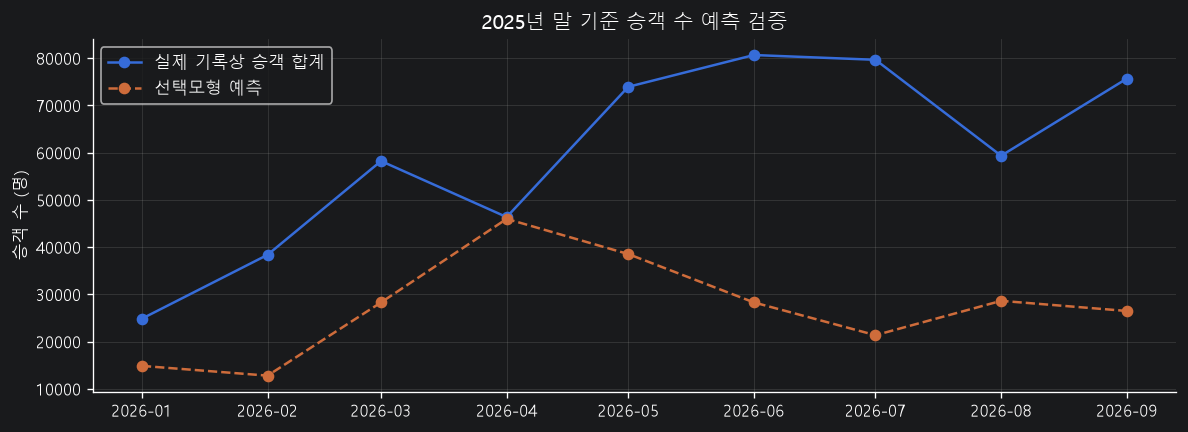

In [7]:
def passenger_prediction(y, name, horizon, seed):
    model = fit_forecaster(y/1000.0, name)
    pred, paths = predict_distribution(model,horizon,seed)
    return pred*1000.0, paths*1000.0

def passenger_scores(actual, pred):
    mask = actual.notna()
    score = metrics(actual.loc[mask], pred.loc[mask])
    return {'평가월수':int(mask.sum()), **score}

selection_y,_ = training_passengers('2024-12-01')
selection_actual = actual_passengers.loc['2025']
selection_preds={};performance=[]
for k,name in enumerate(MODEL_NAMES):
    pred,_=passenger_prediction(selection_y,name,12,FORECAST_SEED+k)
    selection_preds[name]=pred
    performance.append({'단계':'모형 선택 2025','모형':name,**passenger_scores(selection_actual,pred)})
selected_model_name=pd.DataFrame(performance).sort_values(['MAE','RMSE'],kind='stable').iloc[0]['모형']
test_y,_=training_passengers('2025-12-01')
test_actual=actual_passengers.loc['2026']
test_preds={}
for k,name in enumerate(MODEL_NAMES):
    pred,_=passenger_prediction(test_y,name,9,FORECAST_SEED+20+k)
    test_preds[name]=pred
    performance.append({'단계':'최종 검증 2026 1~9월','모형':name,**passenger_scores(test_actual,pred)})
passenger_performance=pd.DataFrame(performance)
display(passenger_performance.round(2))
print('2025년 완전 기록 10개월 MAE로 선택한 모형:',selected_model_name)

def passenger_comparison_table(actual,pred):
    result=pd.DataFrame({'실제승객수':actual,'예측승객수':pred['예측승객수']})
    result['오차_실제빼기예측']=result['실제승객수']-result['예측승객수']
    result['절대오차']=result['오차_실제빼기예측'].abs()
    result['평가포함']=result['실제승객수'].notna()
    result.index.name='연월'
    return result
passenger_selection=passenger_comparison_table(selection_actual,selection_preds[selected_model_name])
passenger_backtest=passenger_comparison_table(test_actual,test_preds[selected_model_name])
display(passenger_selection.round(2));display(passenger_backtest.round(2))
fig,ax=plt.subplots(figsize=(10,3.7))
ax.plot(test_actual.index,test_actual,'o-',label='실제 기록상 승객 합계')
ax.plot(test_actual.index,test_preds[selected_model_name]['예측승객수'],'o--',label='선택모형 예측')
ax.set(title='2025년 말 기준 승객 수 예측 검증',ylabel='승객 수 (명)')
ax.legend();ax.grid(alpha=.2);plt.tight_layout();plt.show()


,예측승객수,80하한,80상한,95하한,95상한
연월,,,,,
2026-10-01,84479.30,72025.02,96813.94,65682.51,103557.67
2026-11-01,75072.49,61230.45,88638.64,53979.35,95983.32
2026-12-01,70881.01,55511.39,86385.52,47060.30,94278.42
2027-01-01,77356.66,60129.50,94615.67,51334.72,103598.50
2027-02-01,78802.68,59636.85,97765.72,49303.10,107841.76
2027-03-01,96726.92,76045.03,117079.52,64765.59,128395.04
2027-04-01,115731.17,92828.58,138207.35,80322.39,150159.35
2027-05-01,113093.44,87476.62,137853.42,74317.10,150322.36
2027-06-01,106201.26,78608.37,132840.46,64254.98,147868.17


,완료월실제승객수,예측부분합계,연간전망,80하한,80상한,95하한,95상한
연도,,,,,,,
2026,537053.0,230432.81,767485.81,733968.63,801255.68,715202.57,818089.39
2027,0.0,1247850.19,1247850.19,931297.95,1555589.68,763199.48,1720013.58


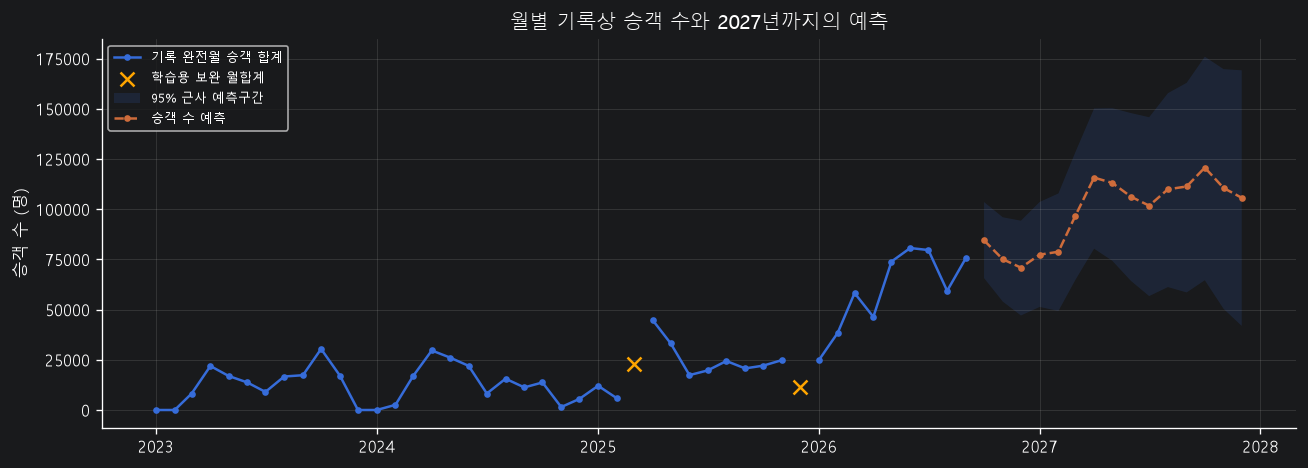

,결측보완방법,보완2건합계,2026검증MAE,2027예측합계
0,이전 동일 선박 25분위,295.25,32476.54,1248532.62
1,이전 동일 선박 중앙값,445.50,32424.27,1247850.19
2,이전 동일 선박 75분위,613.75,32360.15,1247216.37


In [8]:
passenger_future,passenger_paths=passenger_prediction(training_y,selected_model_name,15,FORECAST_SEED+100)
passenger_future.index.name='연월'
annual_rows=[]
for year in [2026,2027]:
    mask=passenger_future.index.year==year
    known=float(test_actual.sum()) if year==2026 else 0.0
    paths=passenger_paths[mask].sum(axis=0)+known
    annual_rows.append({'연도':year,'완료월실제승객수':known,'예측부분합계':passenger_future.loc[mask,'예측승객수'].sum(),'연간전망':known+passenger_future.loc[mask,'예측승객수'].sum(),'80하한':np.quantile(paths,.1),'80상한':np.quantile(paths,.9),'95하한':np.quantile(paths,.025),'95상한':np.quantile(paths,.975)})
passenger_annual=pd.DataFrame(annual_rows).set_index('연도')
display(passenger_future.round(2));display(passenger_annual.round(2))
fig,ax=plt.subplots(figsize=(11,4))
ax.plot(actual_passengers.index,actual_passengers,'o-',ms=3,label='기록 완전월 승객 합계')
missing=actual_passengers.isna()
ax.scatter(training_y.index[missing],training_y.loc[missing],marker='x',color='orange',s=70,label='학습용 보완 월합계')
ax.fill_between(passenger_future.index,passenger_future['95하한'],passenger_future['95상한'],alpha=.14,label='95% 근사 예측구간')
ax.plot(passenger_future.index,passenger_future['예측승객수'],'o--',ms=3,label='승객 수 예측')
ax.set(title='월별 기록상 승객 수와 2027년까지의 예측',ylabel='승객 수 (명)')
ax.legend(fontsize=8);ax.grid(alpha=.2);plt.tight_layout();plt.show()

# Same model, alternative imputed values: not used to reselect the model.
sensitivity_rows=[]
for q,label in [(.25,'이전 동일 선박 25분위'),(.5,'이전 동일 선박 중앙값'),(.75,'이전 동일 선박 75분위')]:
    fy,log=training_passengers('2026-09-01',q)
    ty,_=training_passengers('2025-12-01',q)
    fp,_=passenger_prediction(fy,selected_model_name,15,FORECAST_SEED+100)
    tp,_=passenger_prediction(ty,selected_model_name,9,FORECAST_SEED+20)
    sensitivity_rows.append({'결측보완방법':label,'보완2건합계':log['보완값'].sum(),'2026검증MAE':passenger_scores(test_actual,tp)['MAE'],'2027예측합계':fp.loc['2027','예측승객수'].sum()})
passenger_sensitivity=pd.DataFrame(sensitivity_rows)
display(passenger_sensitivity.round(2))
assert len(selection_y)==24 and len(test_y)==36 and len(training_y)==45
assert passenger_selection['평가포함'].sum()==10 and passenger_backtest['평가포함'].sum()==9
assert np.isfinite(passenger_future.to_numpy()).all() and (passenger_future.to_numpy()>=0).all()
assert len(passenger_future)==15
assert (passenger_future['95하한']<=passenger_future['80하한']).all()
assert (passenger_future['80하한']<=passenger_future['80상한']).all()
assert (passenger_future['80상한']<=passenger_future['95상한']).all()
# 80상하한은 빼기

In [10]:
# 2027년 일정별 승객 정원 합계와 승객 예측 비교 (실제 오차 평가가 아님)
schedule_name = "2027년 크루즈 부산항 입항 예정 스케줄 - sheet1.csv"
schedule_candidates = [Path(schedule_name),Path('upload')/schedule_name,Path('../upload')/schedule_name]
schedule_path = next((p for p in schedule_candidates if p.exists()),None)
if schedule_path is None:raise FileNotFoundError(f'노트북과 같은 폴더에 {schedule_name} 파일을 놓아주세요.')
schedule = pd.read_csv(schedule_path,encoding='utf-8-sig')
schedule['입항예정일']=pd.to_datetime(schedule['입항예정일'],errors='raise')
schedule['선명']=schedule['선명'].str.strip()
schedule['정원']=pd.to_numeric(schedule['승객정원수'].astype(str).str.replace(',','',regex=False).str.strip(),errors='raise')
assert schedule['입항예정일'].notna().all() and schedule['입항예정일'].dt.year.eq(2027).all()
assert schedule['정원'].notna().all() and schedule['정원'].gt(0).all()
assert not schedule.duplicated(['선명','입항예정일']).any()
monthly_capacity=schedule.groupby(schedule['입항예정일'].dt.to_period('M')).agg(예정입항건수=('정원','size'),승객정원합계=('정원','sum'))
monthly_capacity.index=monthly_capacity.index.to_timestamp()
capacity_comparison=passenger_future.loc['2027',['예측승객수']].join(monthly_capacity,how='left')
assert capacity_comparison['승객정원합계'].notna().all()
capacity_comparison=capacity_comparison[['예정입항건수','승객정원합계','예측승객수']]
capacity_comparison['차이_정원빼기예측']=capacity_comparison['승객정원합계']-capacity_comparison['예측승객수']
capacity_comparison['정원대비예측비율(%)']=100*capacity_comparison['예측승객수']/capacity_comparison['승객정원합계']
capacity_comparison['정원합계초과']=capacity_comparison['예측승객수']>capacity_comparison['승객정원합계']
capacity_comparison.index.name='연월'
display(capacity_comparison.round(2))
capacity_total=float(capacity_comparison['승객정원합계'].sum())
passenger_forecast_total=float(capacity_comparison['예측승객수'].sum())
capacity_summary=pd.DataFrame([{'예정입항건수':len(schedule),'승객정원합계':capacity_total,'예측승객합계':passenger_forecast_total,'차이_정원빼기예측':capacity_total-passenger_forecast_total,'정원대비예측비율(%)':100*passenger_forecast_total/capacity_total,'정원초과월수':int(capacity_comparison['정원합계초과'].sum())}])
display(capacity_summary.round(2))


,예정입항건수,승객정원합계,예측승객수,차이_정원빼기예측,정원대비예측비율(%),정원합계초과
연월,,,,,,
2027-01-01,13,65020,77356.66,-12336.66,118.97,True
2027-02-01,28,95790,78802.68,16987.32,82.27,False
2027-03-01,48,89556,96726.92,-7170.92,108.01,True
2027-04-01,49,86072,115731.17,-29659.17,134.46,True
2027-05-01,44,96250,113093.44,-16843.44,117.50,True
2027-06-01,40,114629,106201.26,8427.74,92.65,False
2027-07-01,39,138495,101754.45,36740.55,73.47,False
2027-08-01,40,134754,109921.64,24832.36,81.57,False
2027-09-01,39,126995,111313.71,15681.29,87.65,False


,예정입항건수,승객정원합계,예측승객합계,차이_정원빼기예측,정원대비예측비율(%),정원초과월수
0,441,1248348.0,1247850.19,497.81,99.96,6
